# Tema 24 · Modelos de lenguaje: de predecir la siguiente letra a los LLM

Cómo un modelo que solo predice el siguiente token termina escribiendo, resumiendo y respondiendo.

Este cuaderno es el tema 24 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/aprende/aprendizaje-automatico/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/24-modelos-de-lenguaje-de-predecir-la-siguiente-letra-a-los-llm/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

Este tema entrena o usa redes grandes: en Colab, *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU* lo hace mucho más rápido.

Primero, las bibliotecas que este tema necesita y que Colab no trae (o trae en otra versión):

In [ ]:
!pip install -q accelerate==1.15.0 transformers==5.21.0

# Teoría

## La pregunta

Escribe en tu celular «nos vemos» y el teclado te sugiere «mañana». No entiende tu vida: aprendió que, después de «nos vemos», «mañana» es una de las palabras más frecuentes. Ahora imagina ese mismo truco, adivinar lo que viene, hecho con muchísimo más texto y con un modelo muchísimo más grande. ¿Alcanza para escribir un cuento, resumir un documento o responder una pregunta?

Eso es exactamente un **modelo de lenguaje grande** (LLM, por *large language model*): un programa que, dado un texto, calcula la probabilidad de cada posible **token siguiente**, elige uno, lo pega al final y repite. Nada más. Lo sorprendente es todo lo que sale de ahí, y también los errores que salen de ahí.

En este tema vas a:

- entender un modelo de lenguaje como una cadena de predicciones del siguiente token y medirlo con la entropía cruzada y la perplejidad;
- entrenar en tu computadora un **mini-GPT** por caracteres con el texto de *Don Quijote*;
- generar texto de forma **codiciosa** y con **muestreo**, y controlar la **temperatura**, **top-k** y **top-p**;
- usar un LLM abierto pequeño, Qwen2.5-0.5B-Instruct, con su **plantilla de chat**, y escribir instrucciones (*prompts*) con ejemplos;
- ver con números por qué un LLM puede **equivocarse con total seguridad**.

Necesitas los tokens, los n-gramas y la perplejidad del tema 21 («Texto como datos») y el bloque transformer del tema 23 («Atención y transformers»).

## Actividad: la máquina de escribir probabilística

Esta máquina «leyó» los ocho primeros capítulos del *Quijote* y contó, para cada grupo de letras, qué letra vino después y cuántas veces. Es un modelo de **n-gramas por caracteres**, como los del tema 21: mira los últimos *n* − 1 caracteres (el **contexto**, subrayado) y las barras muestran la probabilidad de cada carácter siguiente. «Siguiente» tira un dado cargado con esas probabilidades.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/24-modelos-de-lenguaje-de-predecir-la-siguiente-letra-a-los-llm/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Con *n* = 4, pulsa «Siguiente» unas diez veces y mira cómo cambian las barras con cada carácter nuevo. A veces hay un favorito claro (después de «Qui» casi siempre viene «j»); otras, muchas opciones parecidas.
2. Baja *n* a 1 y pulsa «Escribir 50». La máquina ya no mira nada: escribe letras sueltas con la frecuencia del español, sin palabras. Sube a 3, a 5 y a 7. ¿Desde qué *n* empiezan a salir palabras reales?
3. Con *n* = 7, escribe 50 caracteres más. A veces copia frases enteras del libro: con tanto contexto, muchas veces solo hay una continuación que vio.
4. Con *n* = 4, pon la temperatura en 0,2 y luego en 2. ¿Qué pasa con las barras y con el texto?
5. Pulsa «Volver a empezar» y repite exactamente los mismos pasos. Sale el mismo texto: el azar de la máquina usa una **semilla**, como `torch.manual_seed`. Cambia la semilla y sale otro.

Lo que viste es todo el tema en pequeño: **más contexto da texto más coherente, y la temperatura cambia creatividad por errores**. Un LLM hace lo mismo, con dos diferencias enormes: en lugar de contar, una red neuronal aprende a **calcular** las probabilidades (así puede usar contextos de miles de tokens que nunca vio tal cual), y en lugar de caracteres usa tokens de subpalabras.

## Un modelo de lenguaje es una cadena de predicciones

Un **modelo de lenguaje** asigna una probabilidad a cada texto. El truco para hacerlo es la **regla de la cadena**: la probabilidad de toda la secuencia es la probabilidad del primer token, por la del segundo dado el primero, por la del tercero dado los dos primeros, y así. Por ejemplo, si un modelo de caracteres dice que el primero es «s» con probabilidad 0,2, que después de «s» viene «o» con 0,5 y que después de «so» viene «l» con 0,4, la palabra «sol» tiene probabilidad 0,2 × 0,5 × 0,4 = 0,04. En símbolos, ∏ es como la Σ, pero **multiplica** en lugar de sumar, y *P*(*a* ∣ *b*) se lee «probabilidad de *a* sabiendo *b*»:

$$P ( {x}_{1} , \ldots , {x}_{T} ) = \prod_{t = 1}^{T} P ( {x}_{t} \mid {x}_{1} , \ldots , {x}_{t - 1} )$$

Por eso basta con un modelo que haga una sola cosa: dado lo anterior, dar las probabilidades del **siguiente** token. Para escribir, se elige un token, se agrega al texto y se vuelve a preguntar. A eso se le llama generación **autorregresiva**: el modelo se alimenta de lo que él mismo escribió.

Para entrenarlo usamos la **entropía cruzada** del tema 8 (con `nn.CrossEntropyLoss`, como en el tema 18), una vez por cada posición: si el token correcto era *x*ₜ y el modelo le dio probabilidad *p*, la pérdida en esa posición es −log *p* (el logaritmo natural, ln, como en la sorpresa del tema 21). El promedio sobre todas las posiciones es la pérdida por token, y su exponencial es la **perplejidad** del tema 21:

$$\text{perplejidad} = \mathrm{exp} ( - \frac{1}{T} \sum_{t = 1}^{T} \log P ( {x}_{t} \mid {x}_{< t} ) )$$

La perplejidad se lee como «entre cuántas opciones duda el modelo, en promedio». Un modelo que elige al azar entre 92 caracteres tiene perplejidad 92; uno que siempre acierta con certeza, perplejidad 1.

## Los datos: *Don Quijote*, carácter por carácter

Usamos el texto completo de *Don Quijote de la Mancha* de Miguel de Cervantes, en español, del Project Gutenberg (libro n.º 2000, dominio público). El código lo baja una sola vez a la carpeta `datos/` y quita la cabecera y el pie en inglés de Project Gutenberg.

In [ ]:
import math
import textwrap
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

ruta = Path("datos/quijote-pg2000.txt")
if not ruta.exists():
    ruta.parent.mkdir(exist_ok=True)
    url = "https://www.gutenberg.org/cache/epub/2000/pg2000.txt"
    urllib.request.urlretrieve(url, ruta)

crudo = ruta.read_text(encoding="utf-8").replace("\r\n", "\n")
# El libro está entre estas dos marcas de Project Gutenberg
inicio = crudo.index("*** START OF THE PROJECT GUTENBERG EBOOK")
inicio = crudo.index("\n", inicio) + 1
fin = crudo.index("*** END OF")
texto = crudo[inicio:fin].strip()

print(f"{len(texto):,} caracteres".replace(",", " "))
pos = texto.index("En un lugar de la Mancha")
print(texto[pos:pos + 70])

2 110 726 caracteres
En un lugar de la Mancha, de cuyo nombre no quiero acordarme, no ha mu


Nuestros tokens serán los **caracteres**: letras, tildes, signos y el salto de línea. Es la tokenización más simple del tema 21. El vocabulario es chico y nunca aparece un token desconocido, pero los textos se vuelven largos (cada palabra son varios tokens).

In [ ]:
letras = sorted(set(texto))
V = len(letras)                       # tamaño del vocabulario
a_id = {c: i for i, c in enumerate(letras)}


def codificar(s):
    return [a_id[c] for c in s]


def decodificar(ids):
    return "".join(letras[i] for i in ids)


datos = torch.tensor(codificar(texto))
# El 90 % del libro para entrenar y el último 10 % para validar
corte = int(0.9 * len(datos))
entreno, valid = datos[:corte], datos[corte:]

print("Caracteres distintos:", V)
print("Sancho ->", codificar("Sancho"))
print(f"Azar puro: pérdida ln({V}) = {math.log(V):.2f}")

Caracteres distintos: 92
Sancho -> [38, 47, 59, 49, 54, 60]
Azar puro: pérdida ln(92) = 4.52


Un modelo que no sabe nada y reparte la probabilidad por igual entre los 92 caracteres tiene pérdida ln 92 ≈ 4,52 por carácter. Ese es el número que hay que bajar.

### Ventanas de texto

El modelo no lee el libro entero de una vez: lee **ventanas** de `T` = 64 caracteres. Cada ventana trae 64 ejemplos de entrenamiento a la vez: el objetivo `y` es la misma ventana corrida un lugar, así que en cada posición el modelo tiene que adivinar el carácter que sigue usando solo los anteriores. En lugar de recorrer el libro por épocas, como con la función `entrenar` del tema 18, sacamos ventanas al azar en cada paso, con un generador con semilla.

In [ ]:
T = 64        # ventana de contexto: cuántos caracteres mira el modelo
B = 32        # ventanas por lote
gen_lotes = torch.Generator().manual_seed(0)


def lote(fuente, gen=gen_lotes):
    """B ventanas al azar de `fuente` y las mismas corridas un lugar."""
    ix = torch.randint(len(fuente) - T - 1, (B,), generator=gen)
    x = torch.stack([fuente[i:i + T] for i in ix])
    y = torch.stack([fuente[i + 1:i + T + 1] for i in ix])
    return x.to(device), y.to(device)


x, y = lote(entreno)
print(x.shape, y.shape)
print("Entrada: ", repr(decodificar(x[0, :24].tolist())))
print("Objetivo:", repr(decodificar(y[0, :24].tolist())))

torch.Size([32, 64]) torch.Size([32, 64])
Entrada:  'ice. De mí sé decir que '
Objetivo: 'ce. De mí sé decir que n'


## El mini-GPT

GPT (*generative pre-trained transformer*) es un **decodificador**: una pila de bloques transformer con **máscara causal**, para que cada posición solo mire hacia atrás. Los bloques son los del tema 23 («Atención y transformers»); aquí va una versión compacta, con la atención de varias cabezas escrita en cuatro líneas. Si algo no te resulta familiar (las consultas, claves y valores, el escalado por √*d*, la conexión residual), vuelve a ese tema. Dos cosas nuevas: el MLP usa **GELU** en lugar de ReLU, una ReLU «suavizada» que en vez de cortar en seco en 0 hace una curva (es la que usan los GPT), y la máscara causal se arma con `triu(1)`, que deja en `True` solo el triángulo de arriba de la diagonal: las posiciones del futuro.

In [ ]:
class Bloque(nn.Module):
    """Un bloque transformer decodificador (tema 23), en versión corta."""

    def __init__(self, d, cabezas):
        super().__init__()
        self.cabezas = cabezas
        self.norma1 = nn.LayerNorm(d)
        self.qkv = nn.Linear(d, 3 * d)     # consultas, claves y valores
        self.salida = nn.Linear(d, d)
        self.norma2 = nn.LayerNorm(d)
        # GELU: una ReLU suavizada
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(),
                                 nn.Linear(4 * d, d))

    def forward(self, x):
        b, t, d = x.shape
        h = self.cabezas
        # Q, K y V completos, cada uno (b, t, d)
        q, k, v = self.qkv(self.norma1(x)).split(d, dim=2)
        # Cada uno se corta en h cabezas de d / h números (view) y las
        # cabezas pasan al frente (transpose):
        # (b, t, d) -> (b, t, h, d / h) -> (b, h, t, d / h)
        q, k, v = [z.view(b, t, h, d // h).transpose(1, 2)
                   for z in (q, k, v)]
        pesos = q @ k.transpose(-2, -1) / math.sqrt(d // h)
        # Máscara causal: nadie mira a las posiciones de más adelante
        # triu(1): True arriba de la diagonal, en las posiciones futuras
        futuro = torch.ones(t, t, dtype=torch.bool, device=x.device)
        pesos = pesos.masked_fill(futuro.triu(1), float("-inf"))
        mezcla = pesos.softmax(dim=-1) @ v
        mezcla = mezcla.transpose(1, 2).reshape(b, t, d)
        x = x + self.salida(mezcla)            # conexión residual
        return x + self.mlp(self.norma2(x))    # conexión residual


class MiniGPT(nn.Module):
    def __init__(self, V, T, d=96, cabezas=4, capas=4):
        super().__init__()
        self.letra = nn.Embedding(V, d)       # un vector por carácter
        self.posicion = nn.Embedding(T, d)    # un vector por posición
        self.bloques = nn.Sequential(
            *[Bloque(d, cabezas) for _ in range(capas)])
        self.norma = nn.LayerNorm(d)
        self.cabeza = nn.Linear(d, V)         # un logit por carácter

    def forward(self, ids):
        pos = torch.arange(ids.shape[1], device=ids.device)
        x = self.letra(ids) + self.posicion(pos)
        return self.cabeza(self.norma(self.bloques(x)))


modelo = MiniGPT(V, T).to(device)
total = sum(p.numel() for p in modelo.parameters())
print(f"Parámetros: {total:,}".replace(",", " "))
logits = modelo(x)
print("Logits:", tuple(logits.shape))
perdida = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1))
print(f"Pérdida antes de entrenar: {perdida.item():.2f}")

Parámetros: 471 452
Logits: (32, 64, 92)
Pérdida antes de entrenar: 4.69


Unos 470 000 parámetros: casi todos están en los cuatro bloques (unos 112 000 cada uno). La salida tiene un vector de 92 logits **por cada posición** de cada ventana: el modelo predice los 64 caracteres siguientes en paralelo, y la máscara causal garantiza que ninguno haga trampa mirando el futuro. Antes de entrenar, la pérdida está cerca de ln 92 ≈ 4,52, como un modelo que adivina al azar.

### Generar: un carácter a la vez

Para escribir, le damos un comienzo, nos quedamos con los logits de la **última** posición, los convertimos en probabilidades con softmax, elegimos un carácter y lo pegamos al final. Si el texto ya pasa de 64 caracteres, el modelo solo ve los últimos 64: esa es su **ventana de contexto**.

Hay dos formas de elegir. La **codiciosa** toma siempre el más probable (`argmax`): da siempre lo mismo. El **muestreo** tira el dado con esas probabilidades (`torch.multinomial`); con un generador con semilla, también da siempre lo mismo, pero cambia si cambias la semilla. El parámetro `temperatura` lo explicamos en la sección siguiente; por ahora, 0 quiere decir «codicioso».

In [ ]:
@torch.no_grad()
def generar(modelo, comienzo, n=120, temperatura=0.8, semilla=0):
    gen = torch.Generator(device=device).manual_seed(semilla)
    ids = torch.tensor([codificar(comienzo)], device=device)
    for _ in range(n):
        # Solo los últimos T caracteres: la ventana del modelo
        logits = modelo(ids[:, -T:])[:, -1, :]
        if temperatura == 0:
            siguiente = logits.argmax(dim=-1, keepdim=True)
        else:
            probs = F.softmax(logits / temperatura, dim=-1)
            siguiente = torch.multinomial(probs, 1, generator=gen)
        ids = torch.cat([ids, siguiente], dim=1)
    return decodificar(ids[0].tolist())


def mostrar(s):
    """Imprime el texto en renglones de 72 caracteres."""
    print(textwrap.fill(s.replace("\n", " "), 72))


mostrar(generar(modelo, "En un lugar ", n=60))

En un lugar mQ»MxCÁí¿ÓBse;a(X3àúCsTGqui«ñ0? of7-jl- COLpU?Tóz:N .5vÉUùUá


Sin entrenar, son caracteres al azar.

### Entrenar

El bucle es el de siempre (tema 18): lote, pérdida, `backward`, paso del optimizador. Cada 250 pasos medimos la pérdida en validación con 10 lotes fijos del último 10 % del libro, que el modelo nunca usa para aprender, y en los pasos 500 y 2000 guardamos una muestra de texto.

Para que el entrenamiento tarde un par de minutos en una CPU, el modelo es chico (470 000 parámetros, ventana de 64) y damos solo **2000 pasos** de 32 ventanas: el modelo ve unos 4 millones de caracteres, menos de dos veces el libro. Con más pasos, más capas o una ventana más larga, la pérdida seguiría bajando; con una GPU (`device = "cuda"`), el mismo código corre mucho más rápido.

In [ ]:
@torch.no_grad()
def perdida_valid(modelo, lotes=10):
    gen = torch.Generator().manual_seed(1)    # siempre los mismos lotes
    total = 0.0
    for _ in range(lotes):
        xv, yv = lote(valid, gen)
        total += F.cross_entropy(modelo(xv).reshape(-1, V),
                                 yv.reshape(-1)).item()
    return total / lotes


optimizador = torch.optim.AdamW(modelo.parameters(), lr=3e-3)
PASOS = 2000
historia = []             # (paso, pérdida de entrenamiento, de validación)
muestras = {0: generar(modelo, "En un lugar ")}

for paso in range(1, PASOS + 1):
    x, y = lote(entreno)
    perdida = F.cross_entropy(modelo(x).reshape(-1, V), y.reshape(-1))
    optimizador.zero_grad()
    perdida.backward()
    optimizador.step()
    if paso % 250 == 0:
        historia.append((paso, perdida.item(), perdida_valid(modelo)))
    if paso in (500, PASOS):
        muestras[paso] = generar(modelo, "En un lugar ")

for paso, ent, val in historia[::2] + historia[-1:]:
    print(f"paso {paso:4d}   entrenamiento {ent:.3f}"
          f"   validación {val:.3f}")

paso  250   entrenamiento 2.075   validación 2.041
paso  750   entrenamiento 1.544   validación 1.666
paso 1250   entrenamiento 1.481   validación 1.544
paso 1750   entrenamiento 1.422   validación 1.493
paso 2000   entrenamiento 1.385   validación 1.464


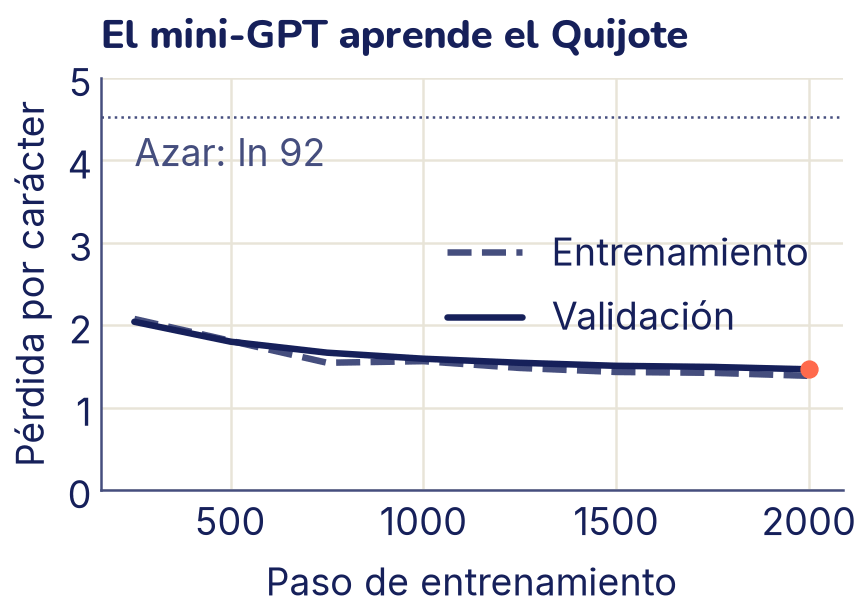

In [ ]:
pasos = [h[0] for h in historia]
# Entrenamiento a rayas, para distinguirlo de validación
plt.plot(pasos, [h[1] for h in historia], color="C2", linestyle="--",
         label="Entrenamiento")
plt.plot(pasos, [h[2] for h in historia], color="C0", label="Validación")
plt.scatter(pasos[-1], historia[-1][2], color="C1", zorder=3, s=40)
plt.axhline(math.log(V), color="C2", linestyle=":", linewidth=1)
plt.text(pasos[0], math.log(V) - 0.15, "Azar: ln 92", color="C2",
         va="top")
plt.ylim(0, 5)
plt.xlabel("Paso de entrenamiento")
plt.ylabel("Pérdida por carácter")
plt.title("El mini-GPT aprende el Quijote")
plt.legend()
plt.show()

Las dos curvas van casi juntas (la de validación, apenas más arriba): con 2000 pasos el modelo todavía no alcanza a memorizar el libro, así que lo que aprende le sirve casi igual para el texto de validación. Una pérdida de 1,46 es una perplejidad de *e*¹·⁴⁶ ≈ 4,3: en promedio, el modelo duda entre unos 4 caracteres, en lugar de 92. Mira cómo cambió lo que escribe (con temperatura 0,8 y la misma semilla):

In [ ]:
for paso, muestra in muestras.items():
    print(f"--- paso {paso}")
    mostrar(muestra)

--- paso 0
En un lugar mQ»MxCÁí¿ÓBse;a(X3àúCsTGqui«ñ0? of7-jl- COLpU?Tóz:N .5vÉUùUá
lbrúXj—M4ùUÚxÚYíÚPp0g:sbbjvxE-ùü5cWdMBXùùhOÉ"—ívxs1p.-QPgàM
--- paso 500
En un lugar mivoleria.  — Y, señor quiinere premolo que mocoz de la
verdilla, de espondió Par a bien mande le merocedió ver pensa mu
--- paso 2000
En un lugar mi cosa, y se alguna se luibre el malde Cartanto, no llevará
la dadora de que vaya: que no había ver llegado mi pensaya


En el paso 0, ruido. En el 500 ya aparecen espacios, comas, la raya de los diálogos y palabras cortas reales («señor», «que», «de la», «bien»), mezcladas con inventadas («quiinere», «premolo»). En el 2000 la mayoría de las palabras existen y la puntuación está en su lugar («no llevará», «que no había»), aunque las frases no dicen nada: el modelo aprendió **cómo se ve** el texto, no de qué trata. Nadie le enseñó qué es una palabra ni una coma: lo sacó de predecir el siguiente carácter unos cuatro millones de veces.

## Elegir el siguiente token: codicioso, temperatura, top-k y top-p

Mira las probabilidades que da el modelo entrenado justo después de «En un lugar de la », con tres valores del parámetro que dejamos pendiente, la `temperatura`:

In [ ]:
@torch.no_grad()
def siguientes(modelo, comienzo, temperatura=1.0, k=5):
    ids = torch.tensor([codificar(comienzo)], device=device)
    logits = modelo(ids[:, -T:])[0, -1]
    probs = F.softmax(logits / temperatura, dim=-1)
    p, i = probs.topk(k)
    # El espacio se muestra como «␣» para que se vea
    return "  ".join(f"{letras[j].replace(' ', '␣')} {q:.2f}"
                     for j, q in zip(i.tolist(), p.tolist()))


for temp in (0.5, 1.0, 1.5):
    print(f"temp = {temp}:  ",
          siguientes(modelo, "En un lugar de la ", temperatura=temp))

temp = 0.5:   m 0.29  c 0.22  v 0.14  p 0.06  s 0.05
temp = 1.0:   m 0.14  c 0.12  v 0.09  p 0.06  s 0.06
temp = 1.5:   m 0.09  c 0.08  v 0.07  p 0.05  s 0.05


### Temperatura

La **temperatura** τ (la letra griega tau; en el código, `temperatura` o `temp`) divide los logits *z* antes del softmax. Usamos τ y no *T* porque *T* ya es la ventana de contexto:

$${p}_{i} = \frac{{e}^{{z}_{i} / \tau}}{\sum_{j} {e}^{{z}_{j} / \tau}}$$

- **τ = 1** deja las probabilidades como el modelo las aprendió.
- **τ menor que 1** agranda las diferencias: el favorito se lleva casi todo. Cuando τ se acerca a 0, el muestreo se vuelve codicioso.
- **τ mayor que 1** achica las diferencias: las opciones raras ganan probabilidad. El texto se vuelve más variado y también más disparatado.

La temperatura **no cambia el orden** de las opciones; solo cuán repartida está la probabilidad. En la actividad, la máquina usa la misma idea con conteos en lugar de logits.

### Codicioso no siempre es mejor

Uno pensaría que elegir siempre lo más probable da el mejor texto. Mira qué hace el mini-GPT con la elección codiciosa:

In [ ]:
mostrar(generar(modelo, "En un lugar ", n=100, temperatura=0))

En un lugar de la mano de la mano de la mano de la mano de la cabeza de
la cabeza de la cabeza de la cabeza de l


Se queda dando vueltas en un bucle: «de la mano de la mano…» y después «de la cabeza de la cabeza…». Cada paso elige lo más probable *en ese paso*, y una vez que entra en una frase muy común, lo más probable es repetirla. Por eso los generadores suelen **muestrear**, con una temperatura entre 0,6 y 1, más o menos.

### Top-k y top-p

Con el muestreo hay otro problema: entre miles de tokens con probabilidad diminuta, sumados, hay bastante probabilidad de que salga alguno absurdo. Dos recortes comunes, que se aplican antes de tirar el dado:

- **top-k**: quedarse solo con los *k* tokens más probables (por ejemplo, *k* = 50) y repartir entre ellos.
- **top-p** (o *nucleus sampling*): quedarse con los más probables hasta que sus probabilidades **sumen** *p* (por ejemplo, 0,9). Si el modelo está seguro, quedan uno o dos tokens; si duda, quedan muchos.

In [ ]:
def recortar(probs, k=None, p=None):
    """Pone en 0 lo que queda fuera del top-k o del top-p y renormaliza."""
    orden, idx = probs.sort(descending=True)
    conservar = torch.ones_like(orden, dtype=torch.bool)
    if k is not None:
        conservar[k:] = False
    if p is not None:
        # Se conserva un token si lo acumulado ANTES de él no llega a p
        antes = orden.cumsum(0) - orden
        conservar &= antes < p
    nuevo = torch.zeros_like(probs)
    nuevo[idx[conservar]] = orden[conservar]
    return nuevo / nuevo.sum()


probs = torch.tensor([0.50, 0.20, 0.15, 0.10, 0.05])
print("top-k = 2:  ", recortar(probs, k=2).numpy().round(3))
print("top-p = 0.8:", recortar(probs, p=0.8).numpy().round(3))

top-k = 2:   [0.714 0.286 0.    0.    0.   ]
top-p = 0.8: [0.588 0.235 0.176 0.    0.   ]


Con top-p = 0,8 sobreviven los tres primeros: 0,50 + 0,20 no llega a 0,8, así que hace falta el tercero (0,50 + 0,20 + 0,15 = 0,85). Después se reparten de nuevo para que sumen 1.

## Un LLM de verdad: Qwen2.5-0.5B-Instruct

Nuestro mini-GPT tiene 470 000 parámetros y leyó un libro. Los LLM que conoces tienen miles de millones de parámetros y leyeron una buena parte del texto público de internet, libros y código. La idea es la misma; cambia la escala, y los tokens son **subpalabras** (BPE, tema 21) en lugar de caracteres.

Vamos a usar **Qwen2.5-0.5B-Instruct**, un LLM abierto de Alibaba Cloud (licencia Apache-2.0, en [Hugging Face](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct)). Es de los más chicos que hay, pero entiende y escribe español. Pesa casi 1 GB: la primera vez se descarga y después queda guardado. Corre en una CPU, aunque cada respuesta tarda unos segundos. Este código necesita `transformers` 5 o más nuevo (el argumento `dtype=` no existe en versiones anteriores). En Colab, si `print(transformers.__version__)` (después de `import transformers`) muestra una versión 4, ejecuta en una celda aparte `!pip install -U "transformers>=5"` y reinicia la sesión del cuaderno.

In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer

nombre = "Qwen/Qwen2.5-0.5B-Instruct"
tok = AutoTokenizer.from_pretrained(nombre)
llm = AutoModelForCausalLM.from_pretrained(nombre, dtype=torch.float32)
llm = llm.to(device).eval()

millones = sum(p.numel() for p in llm.parameters()) / 1e6
print(f"Parámetros: {millones:.0f} millones")
print("Vocabulario:", len(tok), "tokens")
print("Ventana de contexto:", llm.config.max_position_embeddings)
print(tok.tokenize("En un lugar de la Mancha"))

Parámetros: 494 millones
Vocabulario: 151665 tokens
Ventana de contexto: 32768
['En', 'Ġun', 'Ġlugar', 'Ġde', 'Ġla', 'ĠMan', 'cha']


Mil veces más parámetros que el mini-GPT, un vocabulario de más de 150 000 tokens y una ventana de 32 768 tokens (unas cuantas decenas de páginas). La «Ġ» marca un token que empieza con espacio: «Mancha» se parte en «ĠMan» y «cha».

### Las probabilidades del siguiente token

`AutoModelForCausalLM` es exactamente lo que construimos: recibe tokens y devuelve logits para el siguiente. Preguntémosle qué viene después del comienzo del *Quijote*:

In [ ]:
@torch.no_grad()
def logits_siguiente(texto_inicial):
    x = tok(texto_inicial, return_tensors="pt").to(device)
    return llm(**x).logits[0, -1].float().cpu()


inicio_quijote = "En un lugar de la Mancha, de cuyo nombre no quiero"
z = logits_siguiente(inicio_quijote)
favoritos = z.topk(6).indices
for temp in (0.5, 1.0, 1.5):
    p = F.softmax(z / temp, dim=-1)
    # ¿Cuántos tokens hacen falta para juntar el 90 %?
    nucleo = int((p.sort(descending=True).values.cumsum(0) < 0.9).sum()) + 1
    fila = " ".join(f"{tok.decode(i).strip()} {p[i]:.2f}"
                    for i in favoritos)
    print(f"temp={temp}: {fila} | top-p: {nucleo}")

temp=0.5: hablar 0.63 decir 0.10 d 0.06 dar 0.05 revel 0.04 menc 0.03 | top-p: 6
temp=1.0: hablar 0.18 decir 0.07 d 0.05 dar 0.05 revel 0.05 menc 0.04 | top-p: 171
temp=1.5: hablar 0.05 decir 0.02 d 0.02 dar 0.02 revel 0.02 menc 0.02 | top-p: 5341


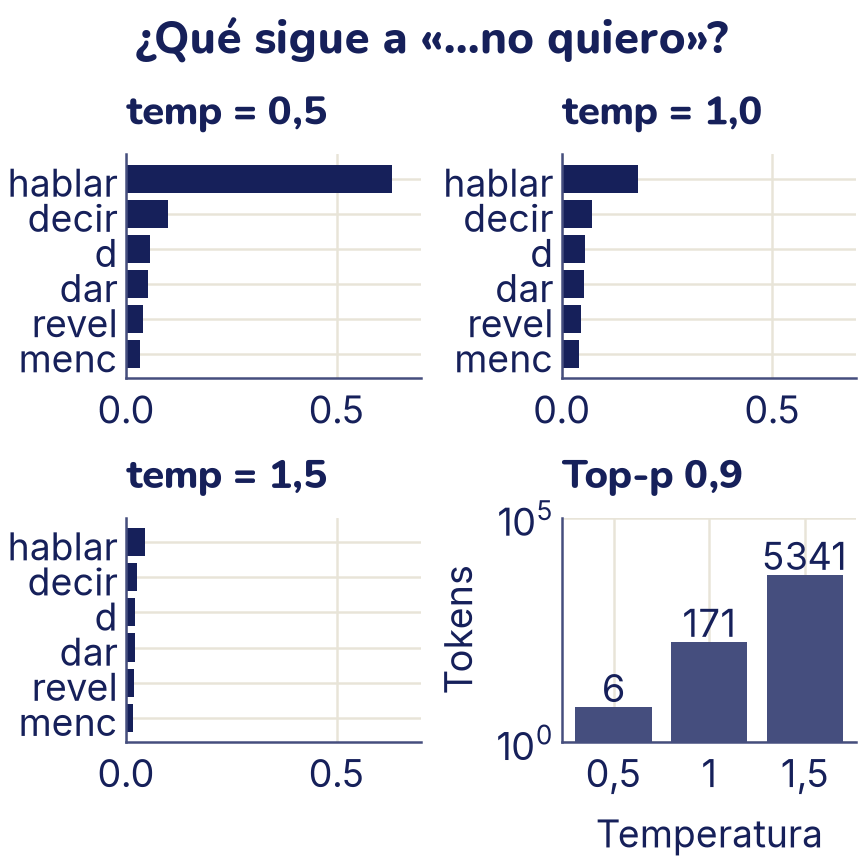

In [ ]:
fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
etiquetas = [tok.decode(i).strip() for i in favoritos]
for eje, temp in zip(ejes.flat, (0.5, 1.0, 1.5)):
    p = F.softmax(z / temp, dim=-1)[favoritos]
    eje.barh(etiquetas[::-1], p.numpy()[::-1], color="C0")
    eje.set_xlim(0, 0.7)
    eje.set_title(f"temp = {temp}".replace(".", ","))
# Cuarto panel: tokens que necesita top-p = 0,9 con cada temperatura
nucleos = []
for temp in (0.5, 1.0, 1.5):
    p = F.softmax(z / temp, dim=-1).sort(descending=True).values
    nucleos.append(int((p.cumsum(0) < 0.9).sum()) + 1)
# Solo para dibujar: el número sobre cada barra y los rótulos
ejes[1, 1].bar(["0,5", "1", "1,5"], nucleos, color="C2")
for i, cuantos in enumerate(nucleos):
    ejes[1, 1].text(i, cuantos * 1.3, cuantos, ha="center")
ejes[1, 1].set_yscale("log")
ejes[1, 1].set_ylim(1, 1e5)
ejes[1, 1].set_title("Top-p 0,9")
ejes[1, 1].set_ylabel("Tokens")
ejes[1, 1].set_xlabel("Temperatura")
fig.suptitle("¿Qué sigue a «…no quiero»?")
plt.show()

Tres cosas para notar:

- El modelo **no** apuesta por «acordarme», la palabra de Cervantes (empieza con el token «ac», que queda en el puesto 87). Su favorito, «hablar», es una continuación razonable del español en general. Un LLM no guarda los textos como en una biblioteca; aprende probabilidades, y a veces algunas frases muy repetidas sí le quedan casi de memoria.
- Con temperatura 1,5, el 90 % de la probabilidad se reparte entre más de 5000 tokens: muestrear ahí da texto mucho más impredecible. Con 0,5, bastan 6.
- El orden de los favoritos es el mismo con las tres temperaturas.

En este tema, igual, todas las respuestas de Qwen se generan de forma **codiciosa** (`do_sample=False`), para que te salgan iguales a las del texto cada vez que corres el código. Lo codicioso puede caer en bucles, como viste con el mini-GPT, pero un modelo grande que da respuestas cortas casi nunca cae en ellos. Con `do_sample=True, temperature=0.7, top_p=0.9` obtendrías respuestas más variadas, distintas en cada corrida (salvo que fijes la semilla).

### La plantilla de chat

Qwen2.5-0.5B-**Instruct** no es solo un modelo que continúa texto. Se entrena en tres etapas, que vale la pena distinguir:

1. **Preentrenamiento**: predecir el siguiente token en una cantidad enorme de texto. Sale un modelo que continúa cualquier texto, como nuestro mini-GPT, pero no sabe que tiene que «responder».
2. **Ajuste por instrucciones**: seguir entrenando con miles de ejemplos de conversación del tipo «pregunta → buena respuesta». Aprende el formato de un asistente.
3. **Alineación**: ajustar las respuestas según lo que las personas prefieren (más útiles, más honestas, sin contenido dañino), por ejemplo con comparaciones hechas por personas.

Una conversación se convierte en texto con una **plantilla de chat**: marcas especiales que separan lo que dice cada uno. El modelo aprendió ese formato en el ajuste por instrucciones, así que hay que usar el mismo:

In [ ]:
mensajes = [{"role": "user", "content": "¿Qué es un modelo de lenguaje?"}]
print(tok.apply_chat_template(mensajes, add_generation_prompt=True,
                              tokenize=False))

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
¿Qué es un modelo de lenguaje?<|im_end|>
<|im_start|>assistant


Hay tres **roles**: `system` (instrucciones generales; si no pones uno, Qwen agrega el suyo, en inglés), `user` (tú) y `assistant` (el modelo). La plantilla termina abriendo el turno del asistente: lo que el modelo «predice» a partir de ahí es su respuesta. Un chat no es más que un texto que el modelo continúa.

In [ ]:
@torch.no_grad()
def preguntar(pregunta, sistema=None, max_tokens=60):
    mensajes = [{"role": "user", "content": pregunta}]
    if sistema:
        mensajes.insert(0, {"role": "system", "content": sistema})
    x = tok.apply_chat_template(mensajes, add_generation_prompt=True,
                                return_tensors="pt", return_dict=True)
    x = x.to(device)
    salida = llm.generate(**x, max_new_tokens=max_tokens,
                          do_sample=False)
    # Solo los tokens nuevos: lo que agregó el modelo
    nuevos = salida[0, x["input_ids"].shape[1]:]
    return tok.decode(nuevos, skip_special_tokens=True)


mostrar(preguntar("Explica en una frase qué es un modelo de lenguaje."))

Un modelo de lenguaje es un tipo de inteligencia artificial que se
encarga de procesar y entender grandes cantidades de información en
forma de texto. Específicamente, estos sistemas utilizan algoritmos de
aprendizaje automático para crear modelos de lenguaje que pueden
interpret


Le pedimos una frase y escribió varias: un modelo chico no siempre respeta las instrucciones de formato. Además, la respuesta quedó cortada en «interpret»: `max_tokens=60` le pasa a `max_new_tokens`, el máximo de tokens nuevos, y se acabó.

## Escribir instrucciones: *prompts*

Un ***prompt*** es el texto que le das al modelo. Con un modelo chico, cómo lo escribes cambia mucho la respuesta. Algunas reglas que funcionan:

- **Sé concreto con la tarea y con el formato**: «responde con una sola palabra», «en una frase», «solo con JSON». **JSON** es un formato de texto para datos, casi igual a un diccionario de Python: `{"nombre": "Ana", "edad": 15}`. El módulo `json` de Python lo convierte en diccionario con `json.loads`.
- **Da ejemplos** (*few-shot*): dos o tres pares de entrada y salida antes del caso real. El modelo continúa el patrón.
- **Pon la información que necesita dentro del prompt**: el modelo no sabe lo que no está en su entrenamiento ni en el texto que le das.
- **Verifica la salida con código**, no a ojo: si pediste JSON, intenta leerlo como JSON.

Por ejemplo, para sacar datos de una frase en un formato que un programa pueda usar:

In [ ]:
import json

pedido = ("Extrae los datos de la frase y responde solo con JSON con las "
          "claves nombre, ciudad y edad.\n"
          "Frase: Me llamo Ana, tengo 15 años y vivo en Cochabamba.")
respuesta = preguntar(pedido)
# Si el modelo envuelve el JSON en un bloque de Markdown, se lo quitamos
limpio = respuesta.strip().removeprefix("```json").removesuffix("```")
print(limpio.strip())

datos_ana = json.loads(limpio)
print(datos_ana["ciudad"], datos_ana["edad"] + 1)

{
  "nombre": "Ana",
  "ciudad": "Cochabamba",
  "edad": 15
}
Cochabamba 16


Qwen devolvió el JSON dentro de un bloque de **Markdown**, el formato de texto con marcas que usan muchos chats para mostrar código: el código va entre tres comillas invertidas, aquí con la palabra `json`. Por eso el código quita esas marcas antes de leerlo. Una **salida estructurada** como esta permite usar un LLM dentro de un programa: el JSON se lee, se revisa (¿tiene las tres claves? ¿la edad es un número?) y se guarda. Si `json.loads` falla, el programa lo sabe y puede volver a preguntar. En los ejercicios vas a comparar tres prompts con 10 casos y contar los aciertos: así se evalúa un prompt, con una tabla, no con un ejemplo que salió bien.

## Cuánto sorprende cada token

Con el mismo modelo podemos hacer lo contrario de generar: tomar una frase ya escrita y calcular qué probabilidad le daba el modelo a **cada** token, dados los anteriores. Los tokens con probabilidad muy baja son los que lo «sorprenden».

In [ ]:
@torch.no_grad()
def prob_por_token(frase):
    ids = tok(frase, return_tensors="pt").input_ids.to(device)
    logp = llm(ids).logits[0, :-1].float().log_softmax(dim=-1)
    # La probabilidad que le dio a cada token real, mirando los de antes
    reales = ids[0, 1:]
    p = logp.gather(1, reales[:, None]).squeeze(1).exp().cpu()
    return [tok.decode(i) for i in reales], p


for final in ("acordarme.", "cocinar."):
    frase = "En un lugar de la Mancha, de cuyo nombre no quiero " + final
    piezas, p = prob_por_token(frase)
    perplejidad = torch.exp(-p.log().mean()).item()
    print(f"«...no quiero {final}»  perplejidad = {perplejidad:.1f}")

print([(t, round(q, 3)) for t, q in zip(piezas, p.tolist())][-5:])

«...no quiero acordarme.»  perplejidad = 26.9
«...no quiero cocinar.»  perplejidad = 41.3
[(' no', 0.149), (' quiero', 0.101), (' coc', 0.0), ('inar', 0.722), ('.', 0.014)]


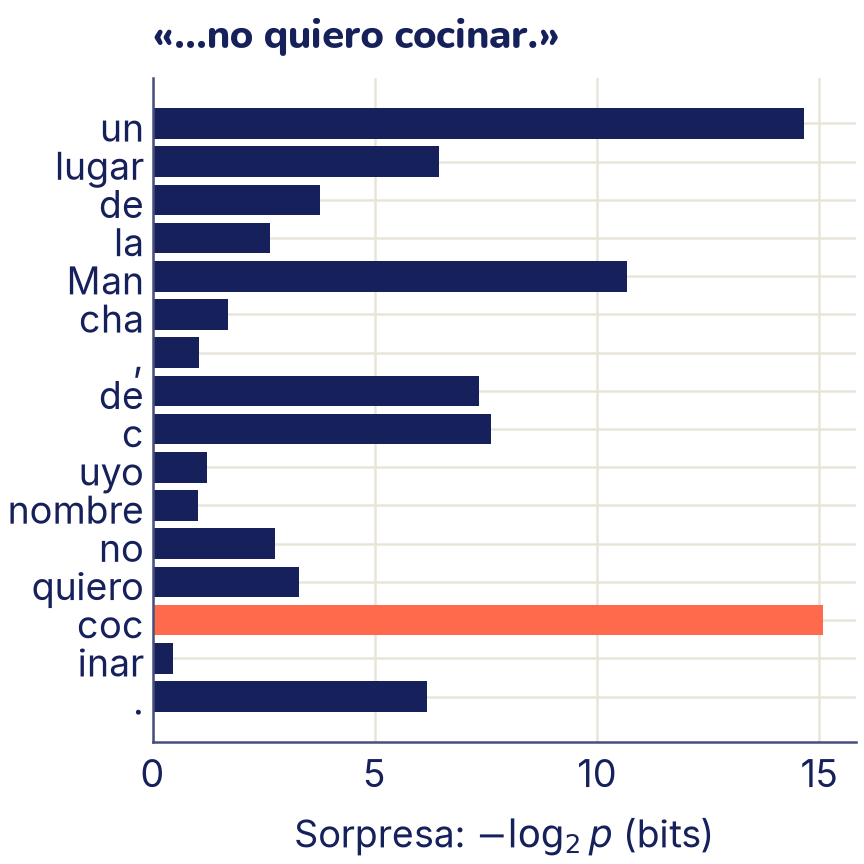

In [ ]:
plt.figure(figsize=(4.8, 4.8))       # más alta: son 16 tokens
etiquetas = [t.strip() or "(espacio)" for t in piezas]
colores = ["C0"] * len(p)
colores[int(p.argmin())] = "C1"          # el token más sorprendente
plt.barh(range(len(p)), (-p.log2()).numpy(), color=colores)
plt.yticks(range(len(p)), etiquetas)
plt.gca().invert_yaxis()
plt.xlabel("Sorpresa: $-\\log_2 p$ (bits)")
plt.title("«...no quiero cocinar.»")
plt.show()

La **sorpresa** de un token se puede medir con −ln *p*, como en el tema 21, o con −log₂ *p*, en **bits**, como en la figura. log₂ cuenta cuántas veces hay que partir la probabilidad por la mitad para llegar a *p*: con *p* = 1/8 hay que partirla tres veces (1 → 1/2 → 1/4 → 1/8), así que la sorpresa es 3 bits. Cada bit de más es la mitad de probabilidad. Lo que muestra la figura:

- El token más sorprendente es «coc»: nadie espera «cocinar» ahí. Una vez que salió «coc», «inar» casi no sorprende (probabilidad 0,72, menos de medio bit): el modelo completa la palabra.
- El comienzo sorprende mucho («un» casi tanto como «coc», y «Man»): sin contexto, hay muchísimas frases posibles. El primer token, «En», ni siquiera tiene probabilidad, porque no hay nada antes de él.
- La frase de Cervantes tiene menor perplejidad (26,9 contra 41,3): al modelo le parece más «normal».

Esta misma cuenta sirve para comparar modelos (el que da menor perplejidad a un texto nuevo lo predice mejor) y para encontrar errores de tipeo o palabras fuera de lugar.

## Los límites: por qué un LLM se equivoca con seguridad

Todo lo que hace un LLM es elegir tokens probables. Eso explica casi todos sus errores.

**Alucinaciones.** Le preguntamos por una novela que **no existe**: el título y el año los inventamos nosotros para esta prueba.

In [ ]:
mostrar(preguntar("Resume en dos frases la novela «El cóndor de cristal», "
                  "publicada en 1987.", max_tokens=50))

La novela "El Cóndor de Cristal" es una obra de ficción escrita por el
autor japonés Akira Kurosawa y publicada en 1987. La historia se
desarrolla en un mundo donde los


El modelo no dice «no conozco ese libro»: inventa un autor (Akira Kurosawa fue un director de cine, no el autor de esta novela) y un argumento, con el mismo tono seguro de una respuesta correcta. Para el modelo, «una novela publicada en 1987 tiene un autor y un argumento» es un patrón muy probable; si el dato no está en lo que aprendió, igual produce algo con esa forma. A esto se le llama **alucinación**.

Los datos concretos, como fechas y números, son terreno peligroso:

In [ ]:
mostrar(preguntar("¿En qué año se fundó la ciudad de La Paz, en Bolivia? "
                  "Responde en una frase."))
mostrar(preguntar("¿Cuánto es 17 por 23? Responde solo con el número."))
print(17 * 23)

La Ciudad de La Paz fue fundada en 1826, hace más de un siglo desde su
fundación como ciudad en Bolivia.
8.954208
391


La Paz se fundó en 1548, no en 1826: el modelo dio una fecha falsa (cerca de la independencia de Bolivia, en 1825, una fecha que seguramente aparecía mucho en sus datos) con total naturalidad. Y a la multiplicación respondió 8.954208, cuando es 391: el modelo no calcula, predice tokens que **parecen** un resultado. Los modelos más grandes se equivocan menos, pero el mecanismo es el mismo. **Cómo verificar**: buscar el dato en una fuente confiable, pedir la fuente (y revisarla: también se inventan fuentes) y, para cuentas, usar código.

Otros límites que conviene tener presentes:

- **Ventana de contexto.** El modelo solo ve los últimos tokens que caben en su ventana (64 caracteres en el mini-GPT, 32 768 tokens en Qwen). Lo que quedó fuera, para él no existe.
- **Fecha de corte.** Lo que sabe es lo que había en sus datos de entrenamiento. No sabe qué pasó después ni lo que hay en tus archivos, salvo que se lo pongas en el prompt.
- **Sesgos.** Aprende de texto escrito por personas, con sus estereotipos. Si en los datos ciertas profesiones aparecen casi siempre con un género, el modelo tiende a repetirlo (en el tema 22 lo viste en los embeddings).
- **Probabilidad no es verdad.** Una respuesta muy probable es una respuesta que suena bien, no necesariamente una correcta.

Nada de esto quiere decir que un LLM no sirva: escribe, resume, traduce y responde muy bien cuando le das la información que necesita y revisas lo importante.

### Modelos abiertos y modelos en la nube

Qwen2.5-0.5B es un **modelo abierto**: sus pesos se descargan y corre en tu computadora. Tus textos no salen de tu máquina, funciona sin internet y lo puedes estudiar por dentro (como hicimos con las probabilidades). A cambio, los modelos que caben en una computadora común son mucho más chicos y se equivocan más.

También hay modelos mucho más grandes que se usan **por internet**, como un servicio en la nube: tu programa manda el prompt a una **API** (una dirección web para programas) y recibe la respuesta. Son más capaces, pero el texto viaja a los servidores de otra empresa (cuidado con los datos personales), suelen requerir una cuenta y pueden tener costo y límites de uso. Las ideas de este tema (tokens, plantilla de chat, temperatura, prompts, verificar) valen igual para los dos.

Dos ideas que vas a escuchar seguido, y que se construyen con lo que viste:

- **RAG** (*retrieval-augmented generation*, generación con búsqueda): antes de preguntar, un buscador encuentra los párrafos relevantes de tus documentos (con los embeddings del tema 22) y se ponen en el prompt. El modelo responde con esa información, no de memoria. El mini-proyecto es una versión simple: el documento entero va en el prompt.
- **Agentes**: un LLM que, además de responder, puede pedir que se ejecute una herramienta (una calculadora, un buscador, un programa) y usar el resultado para seguir. Es una forma de compensar lo que el modelo no sabe hacer bien, como las cuentas.

## Lo que aprendiste y lo que sigue

- Un **modelo de lenguaje** da la probabilidad del siguiente token dados los anteriores; con la regla de la cadena eso alcanza para todo un texto. Se entrena con **entropía cruzada por token** y se mide con la **perplejidad**.
- Un **GPT** es una pila de bloques transformer con **máscara causal**. Nuestro mini-GPT de 470 000 parámetros, en 2000 pasos, pasó de letras al azar a palabras del *Quijote* (pérdida de 4,7 a 1,46 en validación).
- Para generar: **codicioso** (siempre el más probable; puede caer en bucles) o **muestreo**, con **temperatura** (menor que 1 enfoca, mayor que 1 reparte), **top-k** y **top-p**.
- Un **LLM** instruct pasa por preentrenamiento, ajuste por instrucciones y alineación, y conversa a través de una **plantilla de chat** con roles.
- Los **prompts** concretos, con ejemplos y con la información necesaria, funcionan mejor; se evalúan con varios casos y la salida se verifica con código.
- Un LLM puede **alucinar**: produce lo probable, no lo verdadero. Hay que verificar los datos importantes.

En el tema 25 vas a hacer lo contrario de entrenar desde cero: tomar un modelo preentrenado como BERT y ajustarlo a tu propio problema con pocos datos.

# Ejercicios

## Antes de empezar

Varios ejercicios usan lo que construiste en la teoría: `modelo` (el mini-GPT ya entrenado), `generar`, `mostrar`, `codificar`, `decodificar`, `T`, `V`, `recortar`, y para el LLM `tok`, `llm` y `preguntar`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. El entrenamiento tarda un par de minutos en una CPU y Qwen pesa casi 1 GB. Intenta cada ejercicio antes de abrir la respuesta.

## Ejercicios

### 1. La regla de la cadena a mano

Un modelo de lenguaje por caracteres da estas probabilidades: el primer carácter es «s» con probabilidad 0,2; después de «s», viene «o» con 0,5; después de «so», viene «l» con 0,4.

1. ¿Qué probabilidad le da el modelo a la palabra «sol»?
2. ¿Cuál es la pérdida promedio por carácter (entropía cruzada, con logaritmo natural)?
3. ¿Y la perplejidad? Interprétala.

<details>
<summary>Respuesta</summary>

1. Por la regla de la cadena: 0,2 × 0,5 × 0,4 = **0,04**.
2. (−ln 0,2 − ln 0,5 − ln 0,4) / 3 = (1,609 + 0,693 + 0,916) / 3 ≈ **1,073**.
3. *e*¹·⁰⁷³ ≈ **2,92**. Es lo mismo que (1 / 0,04)^(1/3): en promedio, es como si el modelo dudara entre unas 3 opciones igual de probables en cada carácter.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
probs = torch.tensor([0.2, 0.5, 0.4])
perdida = -probs.log().mean()
print(f"P(sol) = {probs.prod():.2f}")
print(f"pérdida = {perdida:.3f}   perplejidad = {perdida.exp():.2f}")

### 2. La temperatura a mano

Un modelo da los logits 2, 1 y 0 a tres tokens. Calcula las probabilidades con temperatura 1, 0,5 y 2 (con calculadora: *e*² ≈ 7,389, *e* ≈ 2,718, *e*⁴ = (*e*²)² ≈ 54,60 y *e*⁰·⁵ ≈ 1,649). ¿Qué pasa con la probabilidad del favorito?

<details>
<summary>Respuesta</summary>

- **τ = 1**: *e*², *e*¹, *e*⁰ = 7,389, 2,718 y 1; suman 11,107. Probabilidades: **0,665, 0,245 y 0,090**.
- **τ = 0,5**: los logits se vuelven 4, 2 y 0: 54,60, 7,389 y 1, que suman 62,99. Probabilidades: **0,867, 0,117 y 0,016**.
- **τ = 2**: los logits se vuelven 1, 0,5 y 0: 2,718, 1,649 y 1, que suman 5,367. Probabilidades: **0,506, 0,307 y 0,186**.

Con temperatura baja el favorito se lleva casi todo (de 0,67 a 0,87); con temperatura alta las tres opciones se acercan. El orden nunca cambia.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
z = torch.tensor([2.0, 1.0, 0.0])
for temp in (1, 0.5, 2):
    print(f"temp = {temp}:", F.softmax(z / temp, dim=0).numpy().round(3))

### 3. Top-k y top-p

Cuatro tokens tienen probabilidades 0,4, 0,3, 0,2 y 0,1. ¿Qué tokens sobreviven y con qué probabilidad, después de renormalizar, con top-k = 3? ¿Y con top-p = 0,6? ¿Y con top-p = 0,95? Compruébalo con `recortar`.

<details>
<summary>Respuesta</summary>

- **top-k = 3**: los tres primeros, que suman 0,9: 0,4/0,9, 0,3/0,9 y 0,2/0,9 = **0,444, 0,333 y 0,222**.
- **top-p = 0,6**: el primero solo (0,4) no llega a 0,6, así que entra el segundo (0,7 ya pasa). Quedan **0,571 y 0,429**.
- **top-p = 0,95**: los tres primeros suman 0,9, que no llega a 0,95: entran **los cuatro**, sin cambios.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
probs = torch.tensor([0.4, 0.3, 0.2, 0.1])
print("top-k = 3:   ", recortar(probs, k=3).numpy().round(3))
print("top-p = 0.6: ", recortar(probs, p=0.6).numpy().round(3))
print("top-p = 0.95:", recortar(probs, p=0.95).numpy().round(3))

### 4. Tres temperaturas en el mini-GPT

Genera 100 caracteres con el mini-GPT a partir de «Dijo Sancho» con temperatura 0,3, 1 y 1,6, con la misma semilla. Describe cada texto: ¿cuál repite más?, ¿cuál tiene más palabras que no existen?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for temp in (0.3, 1.0, 1.6):
    print(f"--- temperatura {temp}")
    mostrar(generar(modelo, "Dijo Sancho", n=100, temperatura=temp))

<details>
<summary>Respuesta</summary>

- Con **0,3** el texto es casi codicioso: casi todas las palabras existen y son de las más comunes («que», «de la», «aquella venta», «la cabeza»), pero se acerca a las repeticiones que viste con la elección codiciosa («de la cabeza de la ma…»).
- Con **1** hay más variedad y más palabras inventadas («espavio», «vala»), aunque la mayoría existen.
- Con **1,6** casi nada es una palabra («Sanchombre», «uiey», «ques7ella»): aparecen mayúsculas fuera de lugar y hasta un número. Las opciones raras ganaron demasiada probabilidad.

</details>

### 5. Más allá de la ventana

Este código le pasa al mini-GPT un texto de 100 caracteres de una sola vez. Ejecútalo, lee el error y explica qué pasó. ¿Por qué `generar` no tiene este problema aunque escriba textos más largos?

*La celda que sigue da un error a propósito: es parte de la explicación.*

In [ ]:
largo = torch.tensor([codificar("En un lugar de la Mancha, " * 4)])
print(largo.shape)
logits = modelo(largo)

torch.Size([1, 104])
Traceback (most recent call last):
  ...
IndexError: index out of range in self


<details>
<summary>Respuesta</summary>

El modelo tiene una tabla `posicion` con un vector para cada una de las `T` = 64 posiciones. Con 104 caracteres, pide el vector de la posición 64, 65… que no existen, y `nn.Embedding` da `IndexError`. Esa es la **ventana de contexto**: el modelo, literalmente, no tiene cómo representar más de 64 posiciones. `generar` le pasa siempre `ids[:, -T:]`, los últimos 64 caracteres, y olvida los anteriores. Los LLM hacen lo mismo con su ventana (32 768 tokens en Qwen2.5-0.5B).

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
logits = modelo(largo[:, -T:])
print(logits.shape)

### 6. Contar los parámetros de un bloque

Con *d* = 96, cuenta a mano los parámetros de un `Bloque` del mini-GPT (pesos y sesgos de cada `nn.Linear`, y los dos de cada `nn.LayerNorm`). Después compruébalo y calcula qué parte del modelo está en los cuatro bloques.

<details>
<summary>Respuesta</summary>

- `qkv`: 96 × 288 + 288 = 27 936.
- `salida`: 96 × 96 + 96 = 9312.
- MLP: 96 × 384 + 384 = 37 248, y 384 × 96 + 96 = 36 960.
- Dos `LayerNorm`: 2 × (96 + 96) = 384.

Total: **111 840** por bloque, unos 12 *d*². Los cuatro bloques son el 95 % del modelo; los embeddings y la cabeza de salida son poco, porque el vocabulario de caracteres es chico. En un LLM con 150 000 tokens, la tabla de embeddings ya pesa mucho más.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
bloque = sum(p.numel() for p in modelo.bloques[0].parameters())
total = sum(p.numel() for p in modelo.parameters())
print(f"Un bloque: {bloque}   cuatro: {4 * bloque / total:.0%}")

### 7. Tres prompts, diez casos

Escribimos diez frases cortas de opinión (inventadas para este ejercicio, cinco positivas y cinco negativas, algunas difíciles). Compara tres prompts para clasificarlas con Qwen:

- **A**: solo la pregunta «¿Esta opinión es positiva o negativa?» y la frase.
- **B**: lo mismo, más «Responde solo con una palabra: positiva o negativa.»
- **C**: como B, pero con dos ejemplos resueltos antes (*few-shot*).

Cuenta una respuesta como acierto si menciona la etiqueta correcta y no la otra. ¿Qué prompt gana? ¿En qué frases fallan?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
casos = [
    ("La comida llegó caliente y muy rica.", "positiva"),
    ("El profe explica tan bien que da gusto ir a clase.", "positiva"),
    ("No esperaba mucho, pero me encantó.", "positiva"),
    ("Barato y funciona, ¿qué más se puede pedir?", "positiva"),
    ("Lo volvería a comprar sin dudar.", "positiva"),
    ("Tardaron dos horas y la pizza llegó fría.", "negativa"),
    ("Se rompió a la semana de usarlo.", "negativa"),
    ("Qué maravilla: otra vez sin internet todo el día.", "negativa"),
    ("No lo recomiendo a nadie.", "negativa"),
    ("Bonito por fuera, pero no sirve para nada.", "negativa"),
]
pregunta = "¿Esta opinión es positiva o negativa?"
formato = "Responde solo con una palabra: positiva o negativa."
ejemplos = ("Opinión: Me encantó la película.\nRespuesta: positiva\n"
            "Opinión: El hotel estaba sucio.\nRespuesta: negativa\n")
prompts = {
    "A": lambda f: f"{pregunta}\n{f}",
    "B": lambda f: f"{pregunta} {formato}\n{f}",
    "C": lambda f: f"{pregunta} {formato}\n{ejemplos}"
                   f"Opinión: {f}\nRespuesta:",
}


def acierta(respuesta, etiqueta):
    r = respuesta.lower()
    otra = "negativa" if etiqueta == "positiva" else "positiva"
    return etiqueta in r and otra not in r


for nombre, armar in prompts.items():
    marcas = [acierta(preguntar(armar(f), max_tokens=10), e)
              for f, e in casos]
    fallos = [i for i, ok in enumerate(marcas) if not ok]
    print(f"Prompt {nombre}: {sum(marcas)}/10   falla en {fallos}")

<details>
<summary>Respuesta</summary>

Pedir el formato ayuda mucho: el prompt A acierta solo 5 de 10 y los otros dos, 9. Sin esa instrucción, el modelo empieza a explicar en lugar de responder y, con 10 tokens, la etiqueta no alcanza a salir («La opinión que proporcionaste parece estar en un estado…»). La frase irónica (la 7, «Qué maravilla: otra vez sin internet») es la más difícil: tiene palabras positivas y un sentido negativo. Diez casos son muy pocos para decidir entre dos prompts que empatan; para eso harían falta muchos más.

</details>

### 8. Cazar una alucinación

Hazle a Qwen preguntas sobre datos concretos que puedas comprobar (autores, fechas, lugares) hasta encontrar una respuesta falsa. Explica por qué el modelo la dio y cómo la verificaste.

<details>
<summary>Respuesta</summary>

Un ejemplo con una novela boliviana clásica, *Juan de la Rosa*, de Nataniel Aguirre (publicada en 1885):

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
mostrar(preguntar("¿Quién escribió la novela boliviana «Juan de la "
                  "Rosa»? Responde en una frase."))

<details>
<summary>Respuesta (sigue)</summary>

La respuesta es falsa y suena segura: la escribió Nataniel Aguirre. El modelo armó un nombre con forma de autor latinoamericano («José María Vargas»), que es un patrón muy probable después de «fue escrita por el autor boliviano», mientras que el dato correcto, poco frecuente en sus datos, no ganó. Se verifica en una fuente confiable (una enciclopedia, el catálogo de una biblioteca, un libro de literatura boliviana), no preguntándole otra vez al mismo modelo. Si tu respuesta salió correcta, prueba con datos más raros: un modelo tan chico se equivoca seguido.

</details>

## Mini-proyecto: un asistente que lee un documento

Vas a armar un asistente que responde preguntas sobre un documento corto, poniendo el documento **dentro del prompt**, y a medir cuántas acierta.

**El documento.** Usa uno corto y tuyo: las reglas de tu colegio, la descripción de un club, las instrucciones de un juego. De referencia, aquí va uno con datos reales de esta ruta de aprendizaje:

In [ ]:
documento = """La ruta de aprendizaje de la OBIA tiene 30 temas en seis fases.
Fase 1, Programar con datos: temas 1 a 5, desde Python hasta NumPy,
Pandas y matemáticas con código.
Fase 2, Aprender de ejemplos: temas 6 a 11. El tema 6 es regresión
lineal y descenso de gradiente; el 11, árboles de decisión y ensambles.
Fase 3, Más modelos, tiempo y estructura: temas 12 a 15 (máquinas de
vectores de soporte, series temporales, clustering y reducción de
dimensiones).
Fase 4, Redes neuronales: temas 16 a 20. El tema 18 presenta PyTorch y
el 20, las redes convolucionales.
Fase 5, Lenguaje y atención: temas 21 a 25. El tema 23 explica la
atención y los transformers; el 24, los modelos de lenguaje.
Fase 6, Ver, oír y crear: temas 26 a 30. El tema 28 trata de audio y el
30 es el proyecto final, junto con la IA responsable.
Cada tema tiene cuatro fichas: Resumen, Teoría, Código y Ejercicios."""

**Pasos.**

1. Escribe 15 preguntas sobre tu documento, cada una con la palabra o el número que debe aparecer en una respuesta correcta (si vale escribirlo de dos formas, como «seis» o «6», acepta las dos). Incluye dos o tres cuya respuesta **no** esté en el documento.
2. Arma un mensaje de sistema que diga «responde solo con la información del documento y, si no está, di exactamente: No está en el documento», y pon el documento y la pregunta en el mensaje del usuario.
3. Genera las 15 respuestas de forma codiciosa y arma una tabla: pregunta, respuesta y acierto (sí o no). Calcula el porcentaje de aciertos.
4. Haz las mismas preguntas **sin** el documento. ¿Cuántas acierta?
5. Mira los fallos: ¿se inventó algo?, ¿confundió dos números parecidos?, ¿respondió algo que no estaba? Cambia el prompt para corregir uno y vuelve a medir.

<details>
<summary>Resultados de referencia, para comprobar los tuyos</summary>

Este código hace los pasos 1 a 4 con el documento de la ruta.

</details>

In [ ]:
# @title Resultados de referencia, para comprobar los tuyos: código (doble clic para verlo)
preguntas = [
    ("¿Cuántos temas tiene la ruta?", "30"),
    ("¿En cuántas fases se divide la ruta?", "seis|6"),
    ("¿Cómo se llama la fase 2?", "aprender de ejemplos"),
    ("¿Qué temas forman la fase 4?", "16"),
    ("¿De qué trata el tema 6?", "regresión lineal"),
    ("¿En qué tema se presenta PyTorch?", "18"),
    ("¿Qué tema explica la atención y los transformers?", "23"),
    ("¿En qué fase está el tema de clustering?", "3"),
    ("¿Cómo se llama la fase 6?", "ver, oír y crear"),
    ("¿Qué tema es el proyecto final?", "30"),
    ("¿De qué trata el tema 28?", "audio"),
    ("¿Cuántas fichas tiene cada tema?", "cuatro|4"),
    ("¿Qué tema trata de árboles de decisión?", "11"),
    ("¿Quién escribió el tema 12?", "no está en el documento"),
    ("¿En qué ciudad se dan las clases?", "no está en el documento"),
]
sistema = ("Responde en una frase corta, solo con la información del "
           "documento. Si la respuesta no está en el documento, di "
           "exactamente: No está en el documento.")


def evaluar(con_documento):
    aciertos = 0
    for i, (q, esperado) in enumerate(preguntas, 1):
        texto = f"Documento:\n{documento}\n\nPregunta: {q}"
        r = preguntar(texto if con_documento else q,
                      sistema=sistema if con_documento else None,
                      max_tokens=25)
        # «seis|6»: vale cualquiera de las dos formas
        ok = any(e in r.lower() for e in esperado.split("|"))
        aciertos += ok
        if con_documento:
            corta = r.replace("\n", " ")[:70]
            print(f"{i:2d} {'sí' if ok else 'no'}  {corta}")
    return aciertos


con = evaluar(True)
sin = evaluar(False)
print(f"Con el documento: {con}/15 ({con / 15:.0%})")
print(f"Sin el documento: {sin}/15")

<details>
<summary>Resultados de referencia, para comprobar los tuyos (sigue)</summary>

- **Con el documento acierta 8 de 15 (53 %); sin él, ninguna.** El modelo no sabe nada de esta ruta: todo lo que acierta lo sacó del prompt. Esa es la idea de RAG.
- **Confunde números cercanos**: dice que el proyecto final es el tema 28, cuando el documento dice 30 (el 28 es el de audio, que está en la misma línea).
- **Responde otra cosa**: a «¿Qué tema explica la atención?» repite la pregunta sin el número, y a «¿Cómo se llama la fase 6?» contesta «Proyecto final».
- **No respeta la instrucción de decir «No está en el documento»**: en la pregunta 14 arma una respuesta con palabras del documento, y en la 15 inventa «Madrid». Las preguntas sin respuesta son las más importantes de medir, porque muestran si el asistente prefiere inventar antes que admitir que no sabe.
- Un modelo de 0,5 B parámetros es muy chico para esta tarea; los modelos más grandes suelen acertar mucho más con el mismo prompt. Para el paso 5, prueba pedir que copie la frase del documento que respalda su respuesta, poner la pregunta antes del documento o agregar un ejemplo resuelto, y vuelve a medir con las mismas 15 preguntas.

</details>

## Errores comunes

- **Olvidar la máscara causal.** Sin ella, cada posición ve el carácter que tiene que predecir: la pérdida de entrenamiento baja casi a cero, pero el modelo no sirve para generar.
- **Correr mal el objetivo.** `y` es `x` corrida **un** lugar. Si usas la misma ventana como entrada y objetivo, el modelo aprende a copiar.
- **Pasarle al modelo más tokens que su ventana.** En el mini-GPT da un `IndexError`; en otros modelos, el principio del texto se pierde o la calidad cae. Recorta a los últimos `T`.
- **Confundir temperatura con calidad.** Temperatura 0 (codicioso) no es «la respuesta correcta»: es la más probable paso a paso, y puede repetirse en bucle. Temperatura alta no es «más creativa» sin costo: también es más disparatada.
- **No usar la plantilla de chat con un modelo instruct.** Si le das el texto suelto, lo continúa como un modelo preentrenado en lugar de responder.
- **Leer solo la respuesta y no la longitud.** Si la respuesta termina a la mitad, se acabó `max_new_tokens`, no es que el modelo no supiera.
- **Evaluar un prompt con un solo ejemplo.** Un caso que salió bien no dice nada; mide con varios casos y una tabla.
- **Creerle a un dato porque suena seguro.** Un LLM produce texto probable, no texto verificado. Fechas, nombres, cifras y citas se comprueban en una fuente.
- **Mandar datos personales a un servicio en la nube sin pensarlo.** Lo que escribes en el prompt viaja a los servidores de otra empresa.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Explicar un modelo de lenguaje con la regla de la cadena y medirlo con la pérdida por token y la perplejidad (ejercicio 1).
- Entrenar en una CPU un modelo de lenguaje pequeño por caracteres, tipo GPT, y explicar su ventana de contexto (teoría, ejercicios 5 y 6).
- Generar texto con muestreo y controlar la temperatura, top-k y top-p (ejercicios 2, 3 y 4).
- Usar un LLM abierto con `transformers` y su plantilla de chat (ejercicio 7 y mini-proyecto).
- Escribir prompts con instrucciones y con ejemplos, y evaluarlos con varios casos (ejercicio 7 y pasos 3 a 5 del mini-proyecto).
- Explicar las alucinaciones y por qué un LLM puede equivocarse con seguridad, y verificar una respuesta (ejercicio 8 y paso 4 del mini-proyecto).